In [1]:
import pancake
import matplotlib.pyplot as plt
from scipy import ndimage
import numpy as np

Target // Adding Source: LHS 1140
Attempting to use SIMBAD Spectral Type: M4.5V


/home/cperrot/anaconda3/envs/stpsf/lib/python3.10/site-packages/pandeia/engine/config.py:213: UserWarning: API parameter, sed_type, missing from input for Phoenix. Using default value of phoenix.
  warn(msg)


Reference // Adding Source: LHS 1140
Attempting to use SIMBAD Spectral Type: M4.5V


/home/cperrot/anaconda3/envs/stpsf/lib/python3.10/site-packages/pandeia/engine/config.py:213: UserWarning: API parameter, sed_type, missing from input for Phoenix. Using default value of phoenix.
  warn(msg)


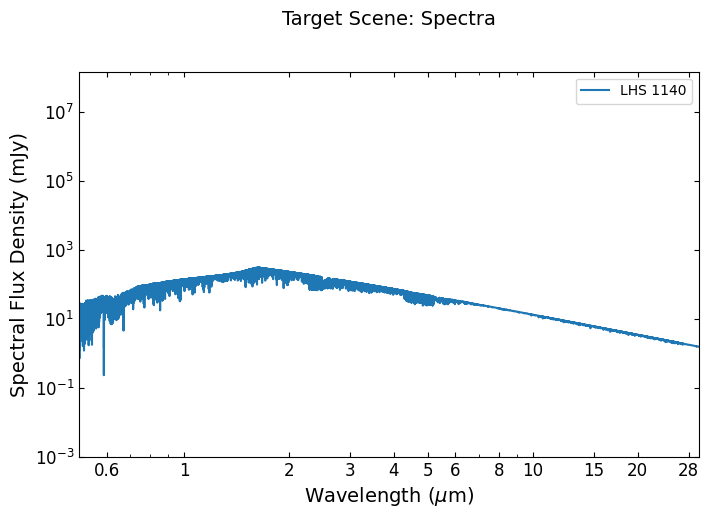

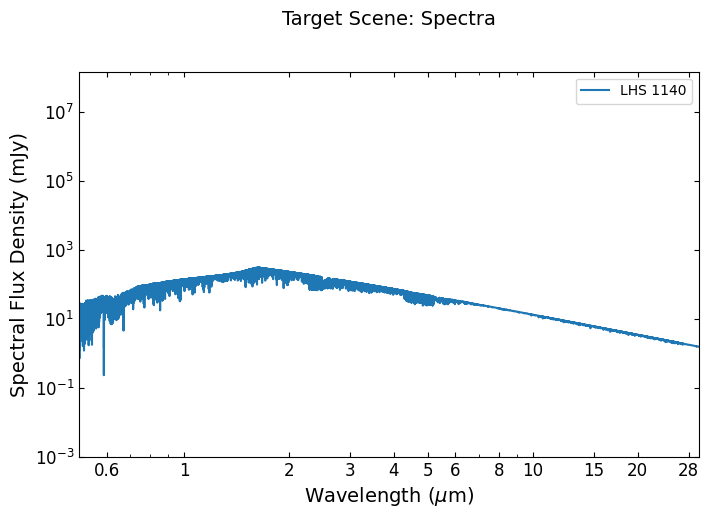

Target // Adding Source: LHS 1140
Attempting to use SIMBAD Spectral Type: M4.5V


/home/cperrot/anaconda3/envs/stpsf/lib/python3.10/site-packages/pandeia/engine/config.py:213: UserWarning: API parameter, sed_type, missing from input for Phoenix. Using default value of phoenix.
  warn(msg)


Reference // Adding Source: LHS 1478
Attempting to use SIMBAD Spectral Type: dM3.5


/home/cperrot/anaconda3/envs/stpsf/lib/python3.10/site-packages/pandeia/engine/config.py:213: UserWarning: API parameter, sed_type, missing from input for Phoenix. Using default value of phoenix.
  warn(msg)


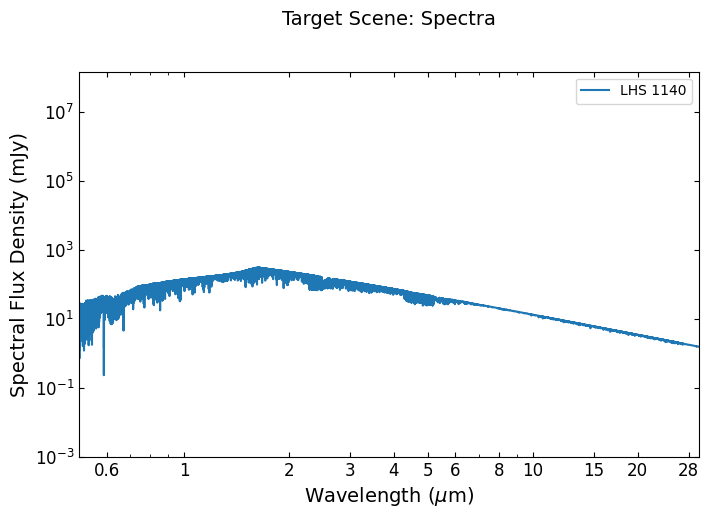

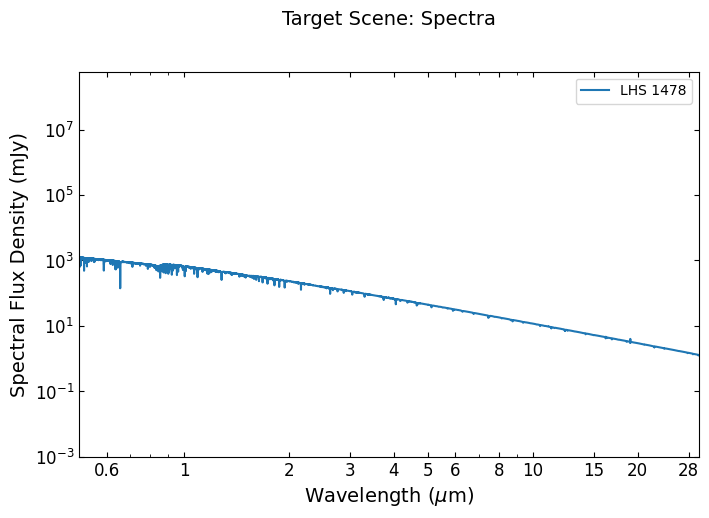

In [2]:
# Define the target scene
target = pancake.scene.Scene('Target')
target.add_source('LHS 1140', kind='simbad')

# Define the reference scene
reference = pancake.scene.Scene('Reference')
reference.add_source('LHS 1140', kind='simbad')

target.plot_source_spectra(title='Target Scene: Spectra')
reference.plot_source_spectra(title='Target Scene: Spectra')


#### obs 2
# Define the target scene
target2 = pancake.scene.Scene('Target')
target2.add_source('LHS 1140', kind='simbad')

# Define the reference scene
reference2 = pancake.scene.Scene('Reference')
reference2.add_source('LHS 1478', kind='simbad')

target2.plot_source_spectra(title='Target Scene: Spectra')
reference2.plot_source_spectra(title='Target Scene: Spectra')





In [3]:
# Initialise an observational sequence
seq = pancake.sequence.Sequence()

# Add target and reference observations
seq.add_observation(target, exposures=[('F1500W', 'optimise', 3600)],mode="imaging", rolls=[0,14])
seq.add_observation(reference, exposures=[('F1500W', 'optimise', 3600)], scale_exposures=target, mode="imaging")

###seq 2
# Initialise an observational sequence
seq2 = pancake.sequence.Sequence()

# Add target and reference observations
seq2.add_observation(target2, exposures=[('F1500W', 'optimise', 3600)],mode="imaging", rolls=[0,14])
seq2.add_observation(reference2, exposures=[('F1500W', 'optimise', 3600)], scale_exposures=target2, mode="imaging")




Optimising Readout // Target // Exposure: F1500W, 3600 seconds
--> Pattern: FASTR1, Number of Groups: 30, Number of Integrations: 139 = 3728s
Optimising Readout // Reference // Exposure: F1500W, 3600 seconds
--> Scaling provided exposure times by relative flux of: "Target"
--> Pattern: FASTR1, Number of Groups: 30, Number of Integrations: 139 = 3728s
Optimising Readout // Target // Exposure: F1500W, 3600 seconds
--> Pattern: FASTR1, Number of Groups: 30, Number of Integrations: 139 = 3728s
Optimising Readout // Reference // Exposure: F1500W, 3600 seconds
--> Scaling provided exposure times by relative flux of: "Target"
--> Pattern: FASTR1, Number of Groups: 33, Number of Integrations: 143 = 4206s


In [4]:
seq.run?

Signature:
seq.run(
    ta_error='saved',
    wavefront_evolution=True,
    on_the_fly_PSFs=False,
    wave_sampling=3,
    save_file=False,
    resume=False,
    verbose=True,
    cache='none',
    cache_path='default',
    offaxis_nircam=[1, 1],
    offaxis_miri=[1, 1],
    debug_verbose=False,
    initial_wavefront_realisation=4,
    wavefront_pa_range='median',
    background='default',
    roll_ta_error='default',
)
Docstring:
Perform all simulations for the exposures defined within this sequence.

Parameters
----------
ta_error : str / float
    Target acquisition errors
    - 'saved' to use a saved random seed of offsets
    - 'random' for a random error
    - int or float for random error with set amplitude in mas
    - 'none' for no error
wavefront_evolution : bool
    Whether to evolve the wavefront error throughout the observation, requires RA and Dec
    for at least one source within the scenes being observed. 
on_the_fly_PSFs : bool
    Whehter to calculate PSF's on the f

In [6]:
results = seq.run(save_file='./simulations.fits',initial_wavefront_realisation=1,wavefront_evolution=True)#, on_the_fly_PSFs=True)

results2 = seq2.run(save_file='./simulations2.fits',initial_wavefront_realisation=8,wavefront_evolution=True)#, on_the_fly_PSFs=True)

Running Simulations...
--> Observation 1/3 // Target_F1500W
--> Observation 2/3 // Target_F1500W
--> Observation 3/3 // Reference_F1500W
Running Simulations...
--> Observation 1/3 // Target_F1500W
--> Observation 2/3 // Target_F1500W
--> Observation 3/3 // Reference_F1500W


Specified reference scenes will not be used for ADI subtraction!
Computing Contrast Curves (ADI)...
Target // F1550C+FQPM1550
--> Performing KLIP Subtraction
--> Extracting Contrast Curve
--> Determining KLIP Throughput
Computing Contrast Curves (RDI)...
Target // F1550C+FQPM1550
-------- Additional rolls can be included using the "target_rolls" parameter/ 
--> Performing KLIP Subtraction
--> Extracting Contrast Curve
--> Determining KLIP Throughput


{'F1550C+FQPM1550': {'separation': array([ 2.23573741,  4.47147482,  6.70721223,  8.94294964, 11.17868705,
         13.41442446, 15.65016187, 17.88589928, 20.12163669, 22.3573741 ,
         24.59311151, 26.82884892, 29.06458633, 31.30032375, 33.53606116,
         35.77179857]),
  'separation_arcsec': array([0.24593112, 0.49186223, 0.73779335, 0.98372446, 1.22965558,
         1.47558669, 1.72151781, 1.96744892, 2.21338004, 2.45931115,
         2.70524227, 2.95117338, 3.1971045 , 3.44303561, 3.68896673,
         3.93489784]),
  'separation_lambdad': array([0.5, 1. , 1.5, 2. , 2.5, 3. , 3.5, 4. , 4.5, 5. , 5.5, 6. , 6.5,
         7. , 7.5, 8. ]),
  'contrast_noklipthrput_nocorothrput': array([nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
         nan, nan, nan]),
  'contrast_noklipthrput': array([nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
         nan, nan, nan]),
  'contrast': array([nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,

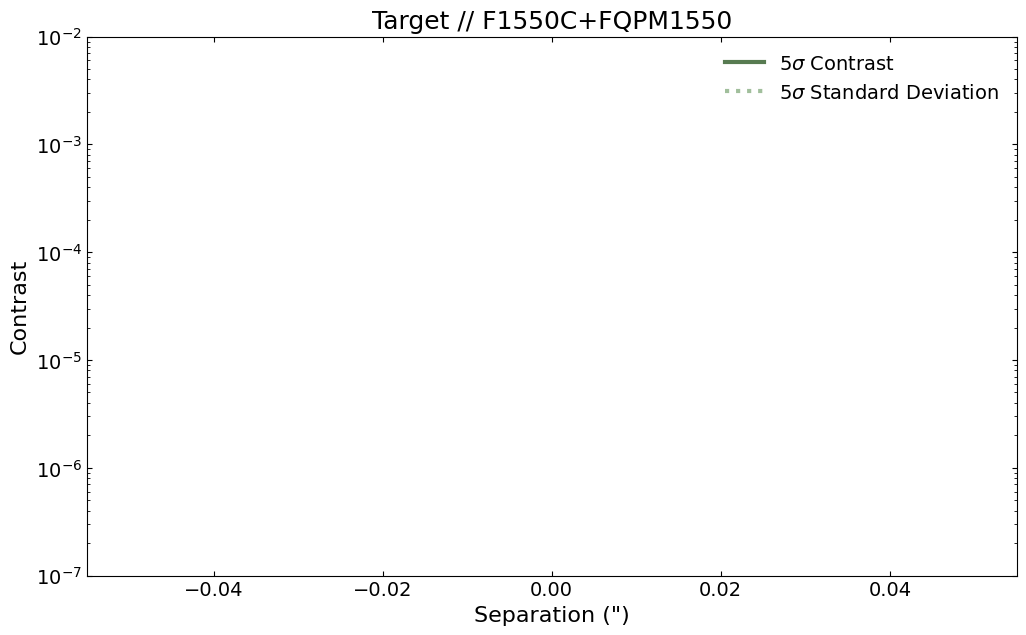

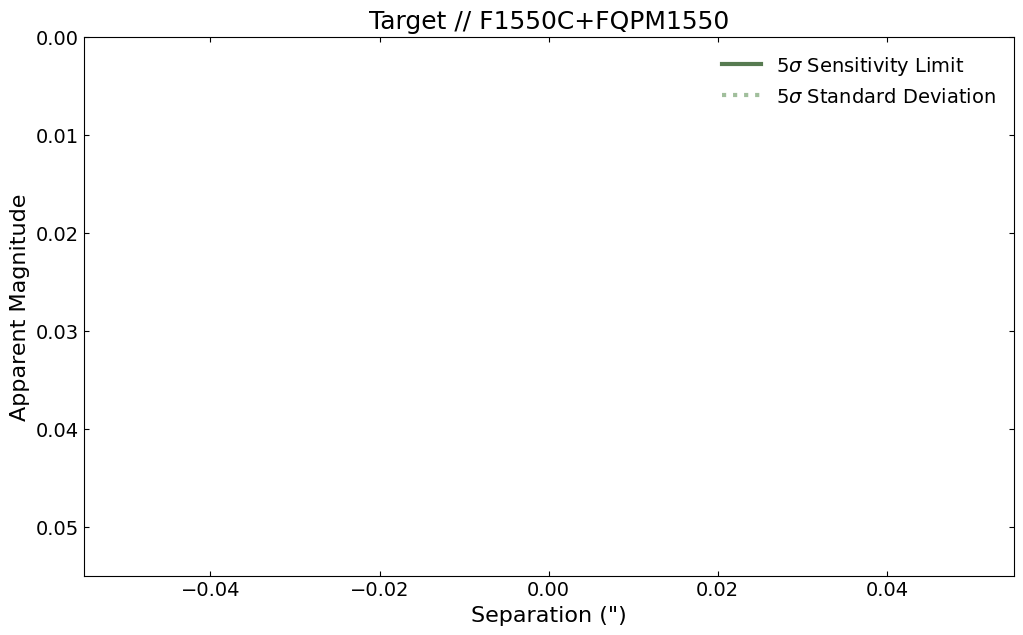

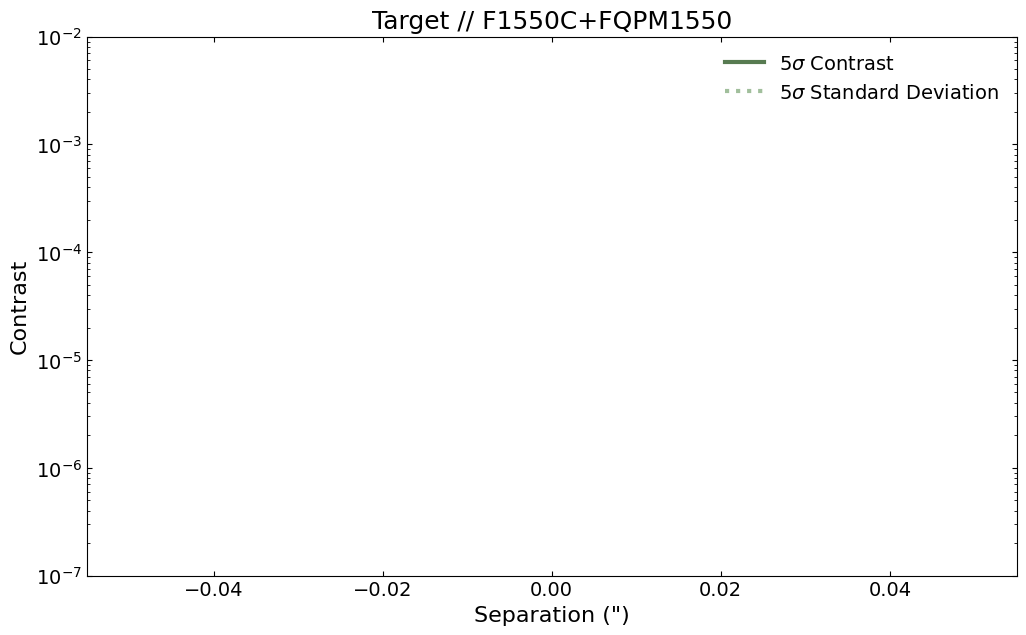

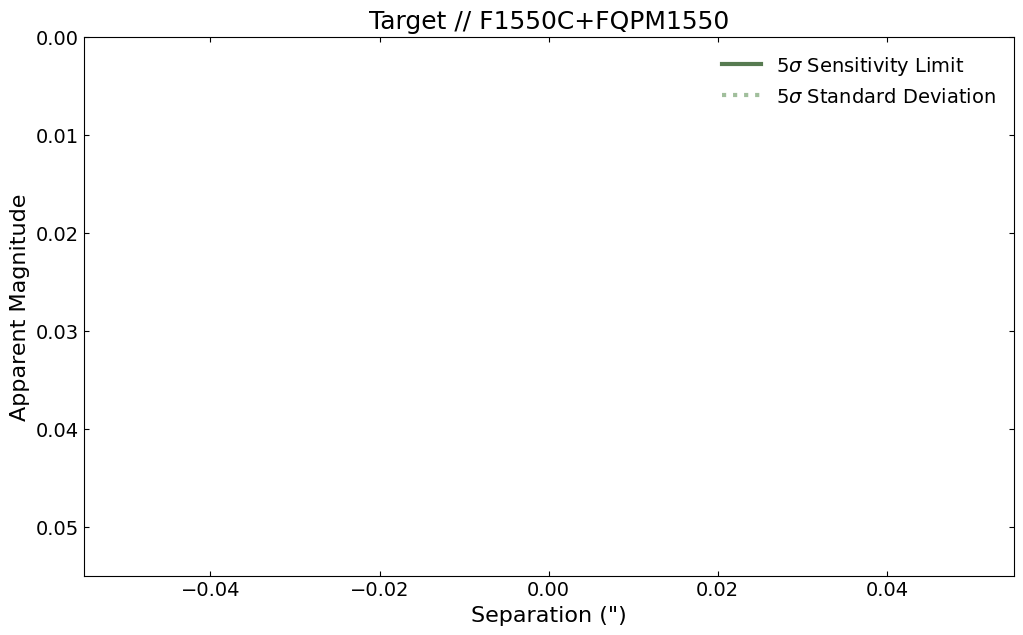

In [5]:
pancake.analysis.contrast_curve(results, target='Target', references='Reference', subtraction='ADI')
pancake.analysis.contrast_curve(results, target='Target', references='Reference', subtraction='RDI')



'2:Target_FQPM1550_F1550C'

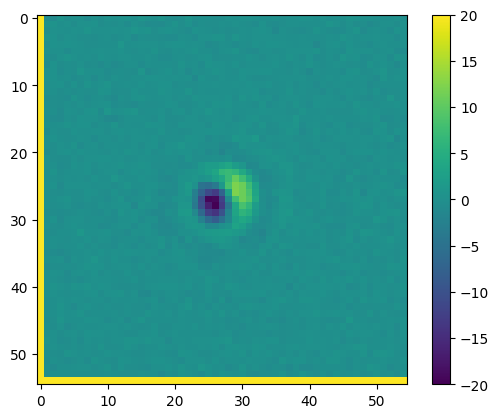

In [7]:
plt.imshow(results[results[1].header["EXTNAME"]].data[0]-ndimage.shift(results[results[2].header["EXTNAME"]].data[0],[-0.07,0.05]),vmin=-20,vmax=20)
plt.colorbar()
plt.show()

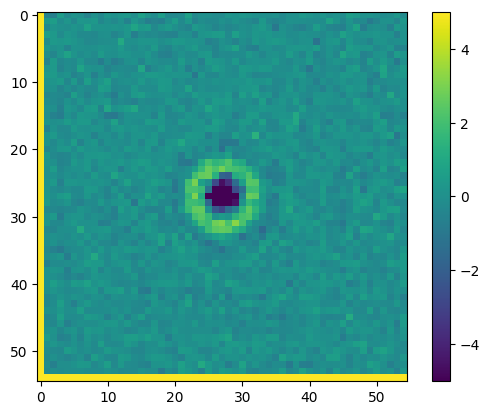

In [8]:
plt.imshow(results[results[1].header["EXTNAME"]].data[0]-ndimage.shift(results[results[2].header["EXTNAME"]].data[0],[-0.074,0.058])*1.00,vmin=-5,vmax=5)
plt.colorbar()
plt.show()

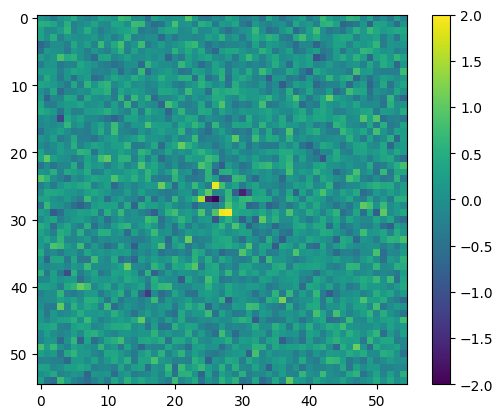

In [9]:
img1 = results[results[1].header["EXTNAME"]].data[0]
img1 -= np.median(img1)
img2 = results2[results2[1].header["EXTNAME"]].data[0]
img2 -= np.median(img2)

plt.imshow(img1-ndimage.shift(img2,[-0.,-0.0])*1.,vmin=-2,vmax=2)
plt.colorbar()
plt.show()